In [6]:
%pip install pandas numpy matplotlib seaborn openpyxl scipy scikit-learn sqlalchemy pyodbc plotly

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\ravip\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
# =====================================================================
# OBJECTIVE 1 : IMPORT LIBRARIES
# =====================================================================
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.decomposition import PCA


In [8]:
# =====================================================================
# OBJECTIVE 2: Load the telecom dataset
# =====================================================================

DATA_PATH = "telcom_data (2).xlsx"
df = pd.read_excel(DATA_PATH)

In [9]:
# =====================================================================
# OBJECTIVE 3 :Initial data exploration
# =====================================================================
print ("shape:", df.shape)

print("\nFirst 5 rows:")
print(df.head())

print("\n Last 5 rows:")
print(df.tail())

print("\nColumn Information:")
print(df.info())

print("\nMissing  values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

shape: (150001, 55)

First 5 rows:
              Bearer Id               Start  Start ms                 End  \
0  13114483460844900352 2019-04-04 12:01:18     770.0 2019-04-25 14:35:31   
1  13114483482878900224 2019-04-09 13:04:04     235.0 2019-04-25 08:15:48   
2  13114483484080500736 2019-04-09 17:42:11       1.0 2019-04-25 11:58:13   
3  13114483485442799616 2019-04-10 00:31:25     486.0 2019-04-25 07:36:35   
4  13114483499480700928 2019-04-12 20:10:23     565.0 2019-04-25 10:40:32   

   End ms  Dur. (ms)          IMSI  MSISDN/Number          IMEI  \
0   662.0  1823652.0  2.082014e+14   3.366496e+10  3.552121e+13   
1   606.0  1365104.0  2.082019e+14   3.368185e+10  3.579401e+13   
2   652.0  1361762.0  2.082003e+14   3.376063e+10  3.528151e+13   
3   171.0  1321509.0  2.082014e+14   3.375034e+10  3.535661e+13   
4   954.0  1089009.0  2.082014e+14   3.369980e+10  3.540701e+13   

  Last Location Name  ...  Youtube DL (Bytes)  Youtube UL (Bytes)  \
0   9164566995485190  ...     

Bearer Id                                        0
Start                                            1
Start ms                                         1
End                                              1
End ms                                           1
Dur. (ms)                                        1
IMSI                                           570
MSISDN/Number                                 1066
IMEI                                           572
Last Location Name                            1153
Avg RTT DL (ms)                              27829
Avg RTT UL (ms)                              27812
Avg Bearer TP DL (kbps)                          1
Avg Bearer TP UL (kbps)                          1
TCP DL Retrans. Vol (Bytes)                  88146
TCP UL Retrans. Vol (Bytes)                  96649
DL TP < 50 Kbps (%)                            754
50 Kbps < DL TP < 250 Kbps (%)                 754
250 Kbps < DL TP < 1 Mbps (%)                  754
DL TP > 1 Mbps (%)             

In [10]:
# =====================================================================
# OBJECTIVE 4 :Standardize column names
# =====================================================================
df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("/", "_", regex=False)
)
print(df.head(2))


              Bearer_Id               Start  Start_ms                 End  \
0  13114483460844900352 2019-04-04 12:01:18     770.0 2019-04-25 14:35:31   
1  13114483482878900224 2019-04-09 13:04:04     235.0 2019-04-25 08:15:48   

   End_ms    Dur._ms          IMSI  MSISDN_Number          IMEI  \
0   662.0  1823652.0  2.082014e+14   3.366496e+10  3.552121e+13   
1   606.0  1365104.0  2.082019e+14   3.368185e+10  3.579401e+13   

  Last_Location_Name  ...  Youtube_DL_Bytes  Youtube_UL_Bytes  \
0   9164566995485190  ...        15854611.0         2501332.0   
1            L77566A  ...        20247395.0        19111729.0   

   Netflix_DL_Bytes  Netflix_UL_Bytes  Gaming_DL_Bytes  Gaming_UL_Bytes  \
0         8198936.0         9656251.0      278082303.0       14344150.0   
1        18338413.0        17227132.0      608750074.0        1170709.0   

   Other_DL_Bytes  Other_UL_Bytes  Total_UL_Bytes  Total_DL_Bytes  
0     171744450.0       8814393.0      36749741.0     308879636.0  
1     52

In [11]:
# =====================================================================
# OBJECTIVE 5 :Remove completely empty columns
# =====================================================================

# Find completely empty columns
empty_columns = df.columns[df.isnull().all()].tolist()

print("Completely empty columns:")
print(empty_columns)

print("\nNumber of completely empty columns:", len(empty_columns))

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

print("\nColumns removed successfully!")
print("Remaining columns:", len(df.columns))

Completely empty columns:
[]

Number of completely empty columns: 0

Columns removed successfully!
Remaining columns: 55


In [12]:
# =====================================================================
# OBJECTIVE 6 :Convert numeric columns
# =====================================================================


numeric_columns = [
    "Start_ms",
    "End_ms",
    "Dur._ms",
    "Avg_RTT_DL_ms",
    "Avg_RTT_UL_ms",
    "Avg_Bearer_TP_DL_kbps",
    "Avg_Bearer_TP_UL_kbps",
    "TCP_DL_Retrans._Vol_Bytes",
    "TCP_UL_Retrans._Vol_Bytes",
    "HTTP_DL_Bytes",
    "HTTP_UL_Bytes",
    "Activity_Duration_DL_ms",
    "Activity_Duration_UL_ms",
    "Total_UL_Bytes",
    "Total_DL_Bytes"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(df[column], errors="coerce")

print("Numeric columns converted successfully!")

print("\nData types after conversion:")
print(df[numeric_columns].dtypes)

Numeric columns converted successfully!

Data types after conversion:
Start_ms                     float64
End_ms                       float64
Dur._ms                      float64
Avg_RTT_DL_ms                float64
Avg_RTT_UL_ms                float64
Avg_Bearer_TP_DL_kbps        float64
Avg_Bearer_TP_UL_kbps        float64
TCP_DL_Retrans._Vol_Bytes    float64
TCP_UL_Retrans._Vol_Bytes    float64
HTTP_DL_Bytes                float64
HTTP_UL_Bytes                float64
Activity_Duration_DL_ms      float64
Activity_Duration_UL_ms      float64
Total_UL_Bytes               float64
Total_DL_Bytes               float64
dtype: object


In [13]:
# =====================================================================
# OBJECTIVE 7 :Treat missing values
# =====================================================================

# Replacing the mean for numeric variables and the mode for categorical variables.

for column in df.select_dtypes(include=np.number).columns:
    df[column] = df[column].fillna(df[column].mean())


#For categorical columns:
for column in df.select_dtypes(include="object").columns:
  if df[column].isnull().sum() > 0:
        df[column] = df[column].fillna(
            df[column].mode()[0]
        )

# Convert Start and End to datetime
df["Start"] = pd.to_datetime(df["Start"], errors="coerce")
df["End"] = pd.to_datetime(df["End"], errors="coerce")

# Fill missing datetime values with the most frequent value
df["Start"] = df["Start"].fillna(df["Start"].mode()[0])
df["End"] = df["End"].fillna(df["End"].mode()[0])


# Check missing values after treatment
print("Total missing values after treatment:", df.isnull().sum().sum())
display(df.isnull().sum())






C:\Users\ravip\AppData\Local\Temp\ipykernel_15504\2071073722.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for column in df.select_dtypes(include="object").columns:


Total missing values after treatment: 0


Bearer_Id                                   0
Start                                       0
Start_ms                                    0
End                                         0
End_ms                                      0
Dur._ms                                     0
IMSI                                        0
MSISDN_Number                               0
IMEI                                        0
Last_Location_Name                          0
Avg_RTT_DL_ms                               0
Avg_RTT_UL_ms                               0
Avg_Bearer_TP_DL_kbps                       0
Avg_Bearer_TP_UL_kbps                       0
TCP_DL_Retrans._Vol_Bytes                   0
TCP_UL_Retrans._Vol_Bytes                   0
DL_TP_<_50_Kbps_%                           0
50_Kbps_<_DL_TP_<_250_Kbps_%                0
250_Kbps_<_DL_TP_<_1_Mbps_%                 0
DL_TP_>_1_Mbps_%                            0
UL_TP_<_10_Kbps_%                           0
10_Kbps_<_UL_TP_<_50_Kbps_%       

In [14]:
# =====================================================================
# OBJECTIVE 8 :Outlier treatment
# =====================================================================
def replace_outliers_with_mean(dataframe):

    numeric_cols = dataframe.select_dtypes(
        include=np.number
    ).columns

    for column in numeric_cols:

        Q1 = dataframe[column].quantile(0.25)
        Q3 = dataframe[column].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        mean_value = dataframe[column].mean()

        dataframe.loc[
            (dataframe[column] < lower_bound) |
            (dataframe[column] > upper_bound),
            column
        ] = mean_value

    return dataframe

# Apply outlier treatment
df = replace_outliers_with_mean(df)

print("Outlier treatment completed successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows after outlier treatment:")
display(df.head())

print("\nDescriptive statistics after outlier treatment:")
display(df.describe())





Outlier treatment completed successfully!
Dataset shape: (150001, 55)

First 5 rows after outlier treatment:


,Bearer_Id,Start,Start_ms,End,End_ms,Dur._ms,IMSI,MSISDN_Number,IMEI,Last_Location_Name,...,Youtube_DL_Bytes,Youtube_UL_Bytes,Netflix_DL_Bytes,Netflix_UL_Bytes,Gaming_DL_Bytes,Gaming_UL_Bytes,Other_DL_Bytes,Other_UL_Bytes,Total_UL_Bytes,Total_DL_Bytes
0,13114483460844900352,2019-04-04 12:01:18,770.0,2019-04-25 14:35:31,662.0,104608.560347,2.082014e+14,3.366496e+10,3.552121e+13,9164566995485190,...,15854611.0,2501332.0,8198936.0,9656251.0,278082303.0,14344150.0,171744450.0,8814393.0,36749741.0,308879636.0
1,13114483482878900224,2019-04-09 13:04:04,235.0,2019-04-25 08:15:48,606.0,104608.560347,2.082019e+14,3.368185e+10,3.579401e+13,L77566A,...,20247395.0,19111729.0,18338413.0,17227132.0,608750074.0,1170709.0,526904238.0,15055145.0,53800391.0,653384965.0
2,13114483484080500736,2019-04-09 17:42:11,1.0,2019-04-25 11:58:13,652.0,104608.560347,2.082016e+14,4.188282e+10,3.528151e+13,D42335A,...,19725661.0,14699576.0,17587794.0,6163408.0,229584621.0,395630.0,410692588.0,4215763.0,27883638.0,279807335.0
3,13114483485442799616,2019-04-10 00:31:25,486.0,2019-04-25 07:36:35,171.0,104608.560347,2.082014e+14,4.188282e+10,3.535661e+13,T21824A,...,21388122.0,15146643.0,13994646.0,1097942.0,799538153.0,10849722.0,749039933.0,12797283.0,43324218.0,846028530.0
4,13114483499480700928,2019-04-12 20:10:23,565.0,2019-04-25 10:40:32,954.0,104608.560347,2.082014e+14,3.369980e+10,3.540701e+13,D88865A,...,15259380.0,18962873.0,17124581.0,415218.0,527707248.0,3529801.0,550709500.0,13910322.0,38542814.0,569138589.0



Descriptive statistics after outlier treatment:


,Start,Start_ms,End,End_ms,Dur._ms,IMSI,MSISDN_Number,IMEI,Avg_RTT_DL_ms,Avg_RTT_UL_ms,...,Youtube_DL_Bytes,Youtube_UL_Bytes,Netflix_DL_Bytes,Netflix_UL_Bytes,Gaming_DL_Bytes,Gaming_UL_Bytes,Other_DL_Bytes,Other_UL_Bytes,Total_UL_Bytes,Total_DL_Bytes
count,150001,150001.000000,150001,150001.000000,150001.000000,1.500010e+05,1.500010e+05,1.500010e+05,150001.000000,150001.000000,...,1.500010e+05,1.500010e+05,1.500010e+05,1.500010e+05,1.500010e+05,1.500010e+05,1.500010e+05,1.500010e+05,1.500010e+05,1.500010e+05
mean,2019-04-26 12:36:40.550523,499.188200,2019-04-27 17:40:06.484243,498.800880,92852.574377,2.082016e+14,3.501433e+10,4.847455e+13,67.089326,10.721812,...,1.163407e+07,1.100941e+07,1.162685e+07,1.100175e+07,4.220447e+08,8.288398e+06,4.211005e+08,8.264799e+06,4.111971e+07,4.546434e+08
min,2019-04-04 12:01:18,0.000000,2019-04-24 22:59:58,0.000000,7142.000000,2.082009e+14,3.360171e+10,4.400152e+11,0.000000,0.000000,...,5.300000e+01,1.050000e+02,4.200000e+01,3.500000e+01,2.516000e+03,5.900000e+01,3.290000e+03,1.480000e+02,9.512288e+06,7.114041e+06
25%,2019-04-25 00:26:01,250.000000,2019-04-26 07:30:10,251.000000,57442.000000,2.082014e+14,3.365182e+10,3.546261e+13,35.000000,3.000000,...,5.833501e+06,5.517965e+06,5.777156e+06,5.475981e+06,2.104733e+08,4.128476e+06,2.101869e+08,4.145943e+06,3.324942e+07,2.431072e+08
50%,2019-04-26 08:51:25,499.000000,2019-04-27 23:02:04,500.000000,86399.000000,2.082016e+14,3.366386e+10,3.572241e+13,54.000000,7.000000,...,1.161602e+07,1.101345e+07,1.164222e+07,1.099638e+07,4.234081e+08,8.291208e+06,4.218030e+08,8.267071e+06,4.112121e+07,4.558409e+08
75%,2019-04-27 18:19:05,749.000000,2019-04-29 07:15:07,750.000000,116737.000000,2.082018e+14,3.368521e+10,8.611970e+13,109.795706,17.662883,...,1.744852e+07,1.651556e+07,1.747048e+07,1.650727e+07,6.331742e+08,1.243162e+07,6.316918e+08,1.238415e+07,4.900537e+07,6.657051e+08
max,2019-04-29 07:28:43,999.000000,2019-04-30 23:59:27,999.000000,244900.000000,2.082022e+14,4.188282e+10,9.900120e+13,221.000000,39.000000,...,2.325910e+07,2.201196e+07,2.325919e+07,2.201196e+07,8.434419e+08,1.655879e+07,8.434425e+08,1.655882e+07,7.271475e+07,9.029696e+08
std,NaN,288.610872,NaN,288.096693,49348.957306,3.310759e+08,3.052711e+09,2.237359e+13,39.123157,8.741881,...,6.710569e+06,6.345423e+06,6.725218e+06,6.359490e+06,2.439675e+08,4.782700e+06,2.432050e+08,4.769004e+06,1.119712e+07,2.441421e+08


In [15]:
#=====================================================================
# OBJECTIVE 9 : Create application data
# =====================================================================
applications = {
    "Social_Media": [
        "Social_Media_DL_Bytes",
        "Social_Media_UL_Bytes"
    ],

    "Google": [
        "Google_DL_Bytes",
        "Google_UL_Bytes"
    ],

    "Email": [
        "Email_DL_Bytes",
        "Email_UL_Bytes"
    ],

    "YouTube": [
        "Youtube_DL_Bytes",
        "Youtube_UL_Bytes"
    ],

    "Netflix": [
        "Netflix_DL_Bytes",
        "Netflix_UL_Bytes"
    ],

    "Gaming": [
        "Gaming_DL_Bytes",
        "Gaming_UL_Bytes"
    ],

    "Other": [
        "Other_DL_Bytes",
        "Other_UL_Bytes"
    ]
}

# Create total data for each application
for app, columns in applications.items():
    df[app + "_Total"] = df[columns].sum(axis=1)


# Display application columns
application_total_columns = [
    "Social_Media_Total",
    "Google_Total",
    "Email_Total",
    "YouTube_Total",
    "Netflix_Total",
    "Gaming_Total",
    "Other_Total"
]

print("Application data created successfully!")

print("\nApplication total columns:")
print(application_total_columns)

print("\nFirst 5 rows of application data:")
display(df[application_total_columns].head())


Application data created successfully!

Application total columns:
['Social_Media_Total', 'Google_Total', 'Email_Total', 'YouTube_Total', 'Netflix_Total', 'Gaming_Total', 'Other_Total']

First 5 rows of application data:


,Social_Media_Total,Google_Total,Email_Total,YouTube_Total,Netflix_Total,Gaming_Total,Other_Total
0,1570185.0,2905912.0,3701304.0,18355943.0,17855187.0,292426453.0,180558843.0
1,1933278.0,4414096.0,937385.0,39359124.0,35565545.0,609920783.0,541959383.0
2,1726277.0,10229119.0,3363124.0,34425237.0,23751202.0,229980251.0,414908351.0
3,657493.0,11811761.0,2070983.0,36534765.0,15092588.0,810387875.0,761837216.0
4,912788.0,7748843.0,2110349.0,34222253.0,17539799.0,531237049.0,564619822.0


        EXPLORATORY DATA ANALYSIS

1. UNIVARIATE ANALYSIS
----------------------


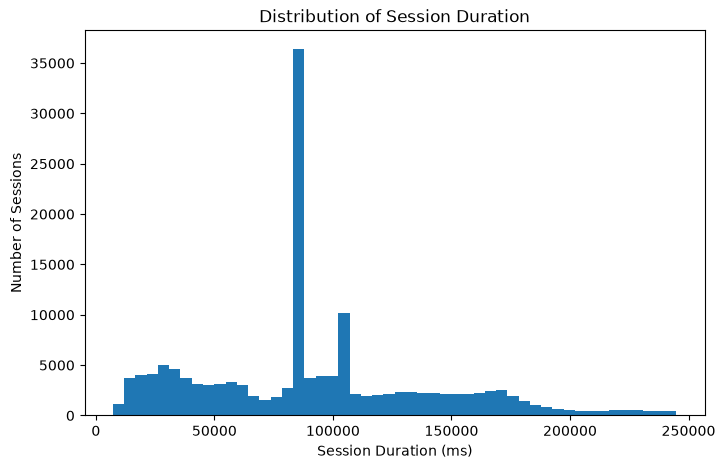

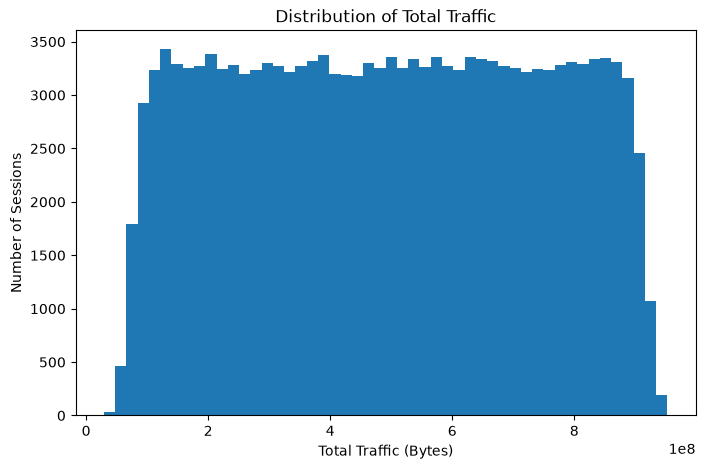


2. APPLICATION USAGE ANALYSIS
-----------------------------


,Total_Data_Bytes
Gaming_Total,6.455040e+13
Other_Total,6.440523e+13
YouTube_Total,3.396545e+12
Netflix_Total,3.394314e+12
Google_Total,1.171102e+12
Email_Total,3.388676e+11
Social_Media_Total,2.742394e+11


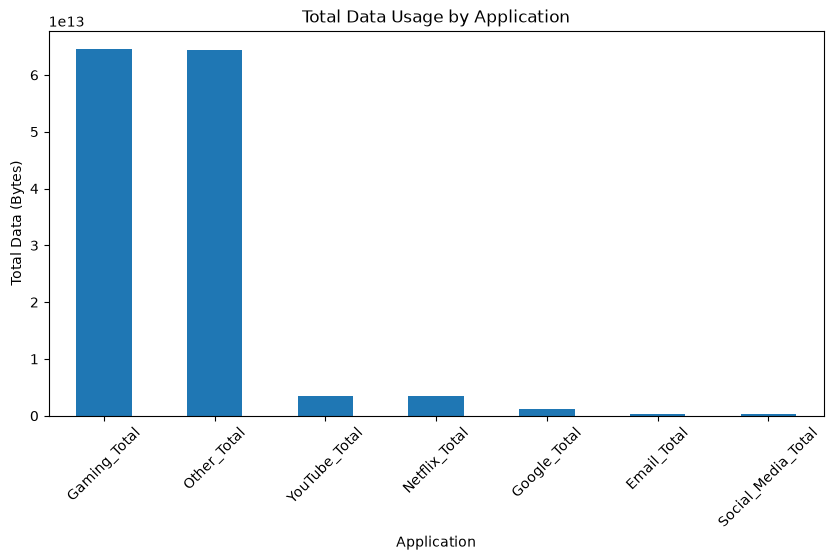


3. BIVARIATE ANALYSIS
---------------------


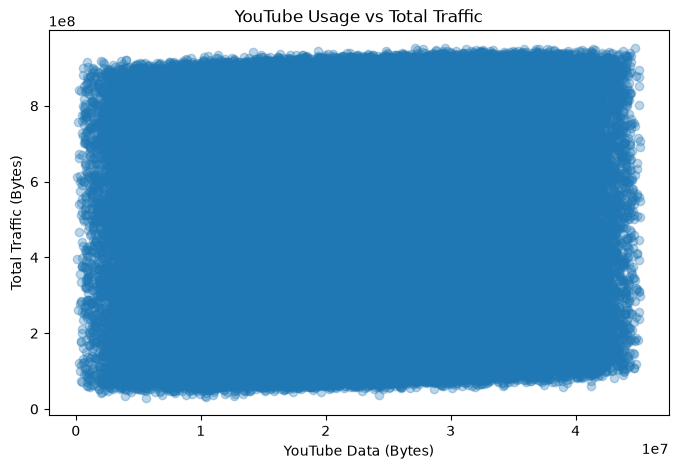


4.TRIVARIATE ANALYSIS
---------------------


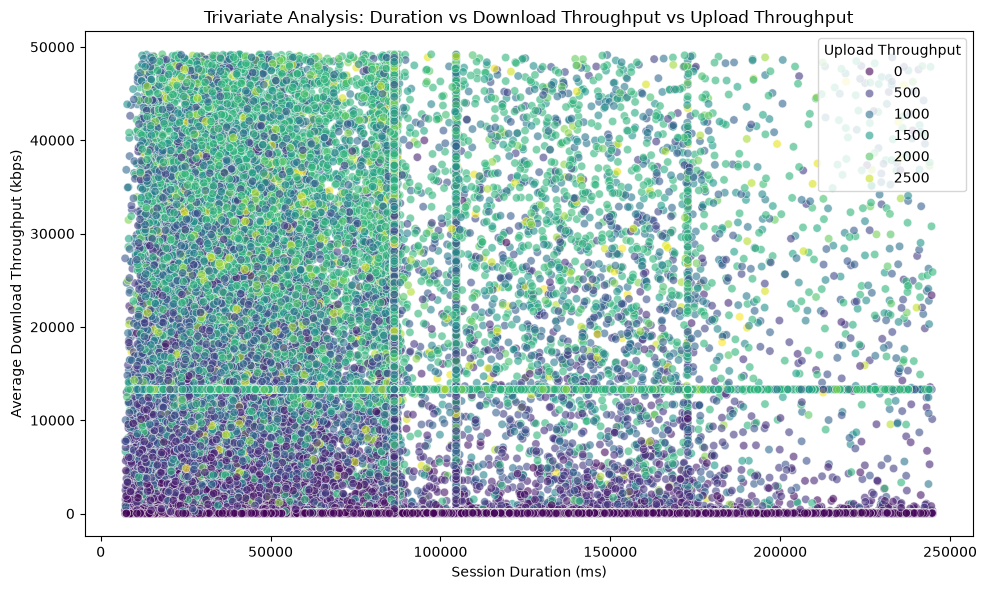

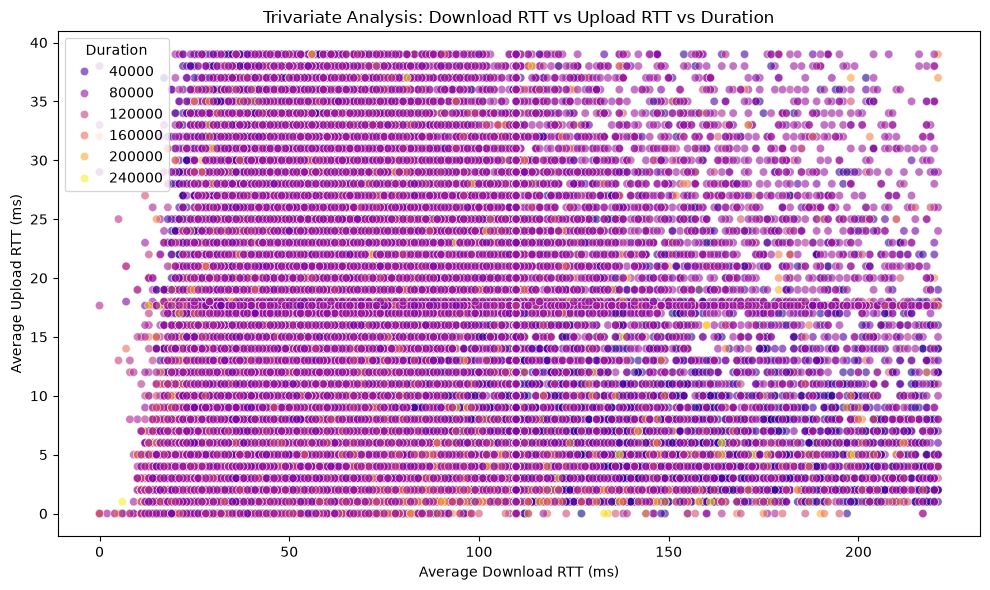


5.MULTIVARIATE ANALYSIS
---------------------
Correlation Matrix:


,Dur._ms,Avg_RTT_DL_ms,Avg_RTT_UL_ms,Avg_Bearer_TP_DL_kbps,Avg_Bearer_TP_UL_kbps
Dur._ms,1.000000,0.006698,-0.005671,-0.241984,-0.265451
Avg_RTT_DL_ms,0.006698,1.000000,0.454233,0.061935,0.070066
Avg_RTT_UL_ms,-0.005671,0.454233,1.000000,0.291661,0.326977
Avg_Bearer_TP_DL_kbps,-0.241984,0.061935,0.291661,1.000000,0.748890
Avg_Bearer_TP_UL_kbps,-0.265451,0.070066,0.326977,0.748890,1.000000


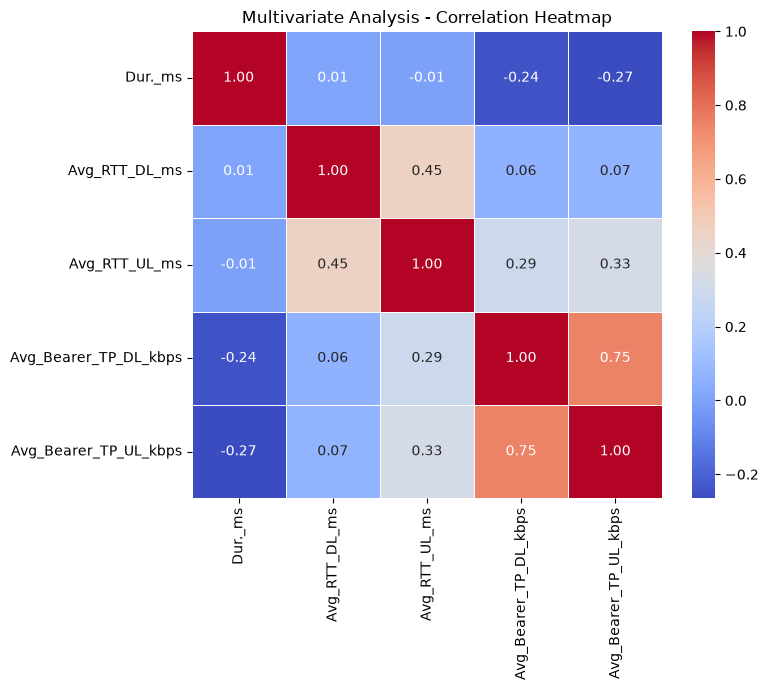

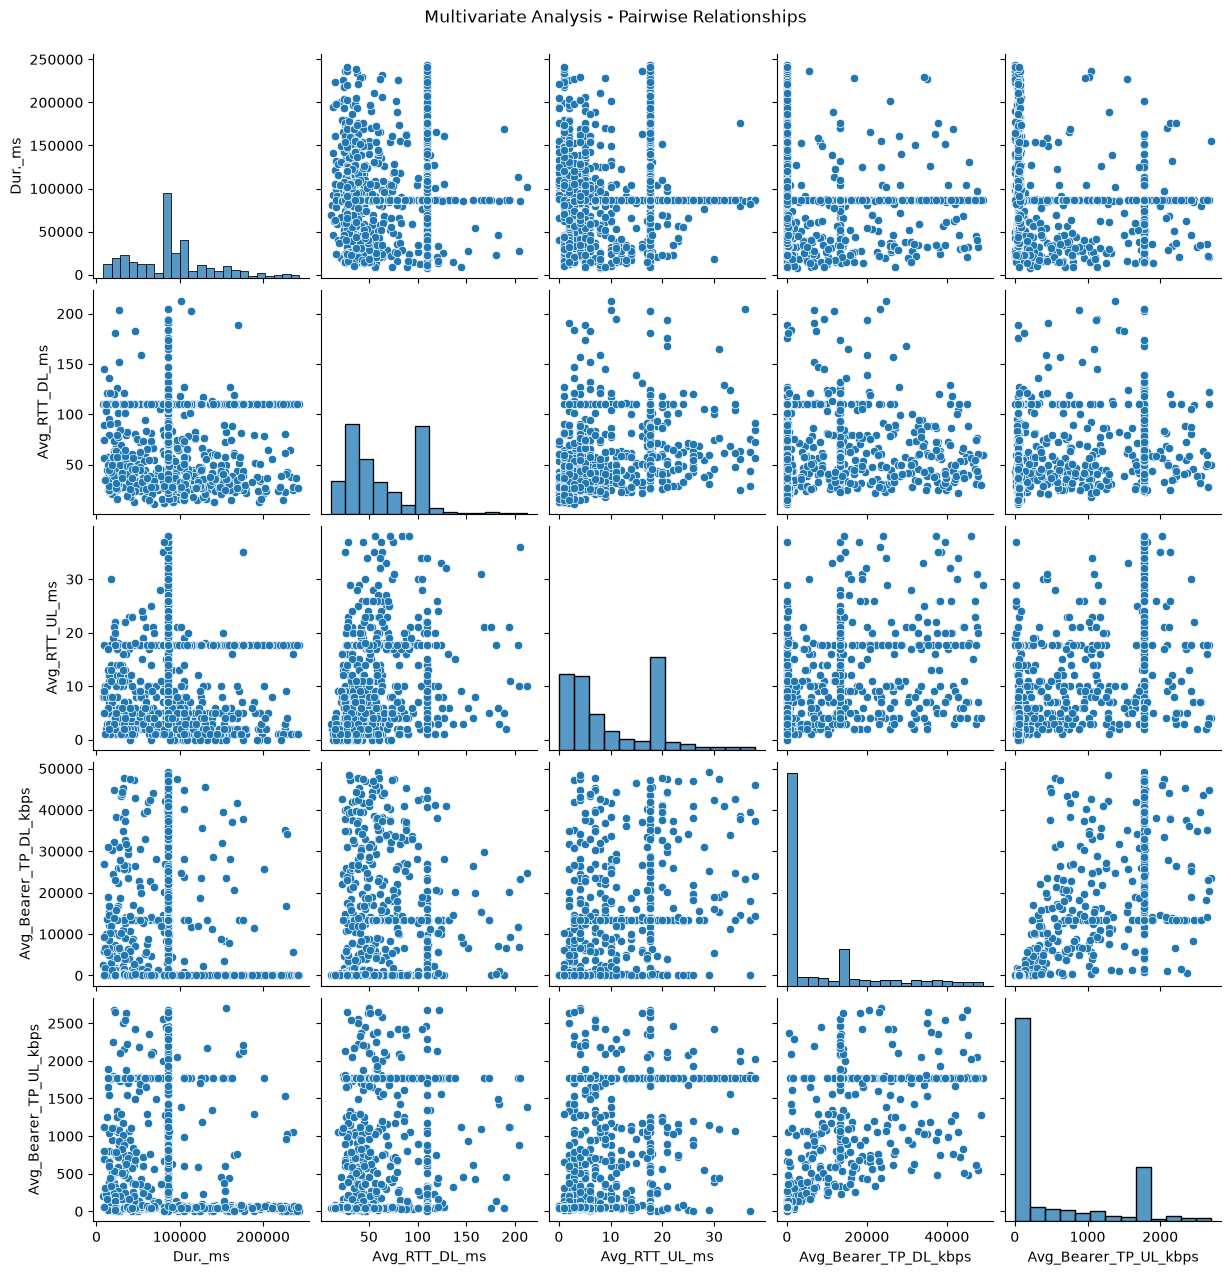


6. DECILE ANALYSIS
------------------


,Duration_Decile,Average_Duration_ms,Average_Traffic_Bytes
0,1,19642.162912,4.958824e+08
1,2,35987.529302,4.963671e+08
2,3,57651.882823,4.984437e+08
3,4,85014.948135,4.936309e+08
4,5,87625.794845,4.951307e+08
5,6,100996.013991,4.944551e+08
6,7,118706.616323,4.936897e+08
7,8,149084.904267,4.977198e+08
8,9,191413.747067,4.988582e+08



7. CORRELATION ANALYSIS
-----------------------


,Social_Media_Total,Google_Total,Email_Total,YouTube_Total,Netflix_Total,Gaming_Total,Other_Total,Total_Traffic_Bytes
Social_Media_Total,1.000000,-0.001708,0.004032,0.000548,0.001013,0.001082,0.006065,0.005381
Google_Total,-0.001708,1.000000,-0.000412,0.002277,-0.001902,-0.000994,-0.001727,0.013304
Email_Total,0.004032,-0.000412,1.000000,-0.002919,0.001029,-0.000644,-0.001299,0.003782
YouTube_Total,0.000548,0.002277,-0.002919,1.000000,0.002882,-0.002999,0.002969,0.034672
Netflix_Total,0.001013,-0.001902,0.001029,0.002882,1.000000,-0.003109,-0.009033,0.034557
Gaming_Total,0.001082,-0.000994,-0.000644,-0.002999,-0.003109,1.000000,-0.002661,0.998264
Other_Total,0.006065,-0.001727,-0.001299,0.002969,-0.009033,-0.002661,1.000000,-0.002453
Total_Traffic_Bytes,0.005381,0.013304,0.003782,0.034672,0.034557,0.998264,-0.002453,1.000000


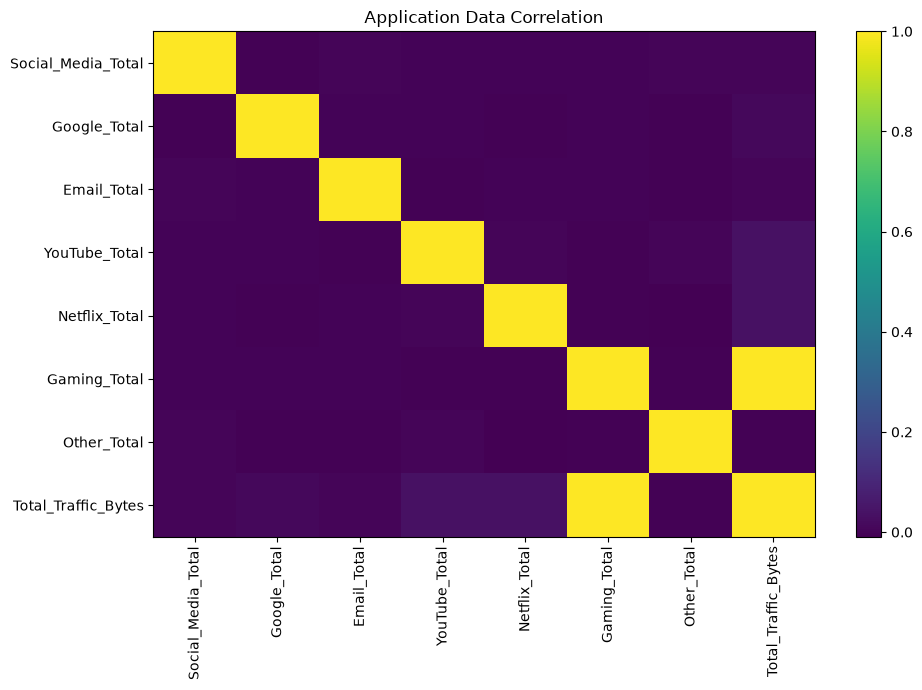


8. PCA ANALYSIS
---------------


,Principal_Component,Explained_Variance_Ratio
0,PC1,0.144360
1,PC2,0.143751
2,PC3,0.143603
3,PC4,0.142883
4,PC5,0.142624
5,PC6,0.141885
6,PC7,0.140894



             EDA COMPLETED SUCCESSFULLY!


In [ ]:
# ============================================================
# OBJECTIVE 10 : EDA - EXPLORATORY DATA ANALYSIS
# ============================================================

print("============================================================")
print("        EXPLORATORY DATA ANALYSIS")
print("============================================================")


# ------------------------------------------------------------
# 1. UNIVARIATE ANALYSIS
# ------------------------------------------------------------

print("\n1. UNIVARIATE ANALYSIS")
print("----------------------")

# Session Duration
plt.figure(figsize=(8, 5))

plt.hist(
    df["Dur._ms"].dropna(),
    bins=50
)

plt.xlabel("Session Duration (ms)")
plt.ylabel("Number of Sessions")
plt.title("Distribution of Session Duration")

plt.show()


# Total Traffic
if "Total_Traffic_Bytes" not in df.columns:
    df["Total_Traffic_Bytes"] = (
        df["Total_DL_Bytes"] +
        df["Total_UL_Bytes"]
    )

plt.figure(figsize=(8, 5))

plt.hist(
    df["Total_Traffic_Bytes"].dropna(),
    bins=50
)

plt.xlabel("Total Traffic (Bytes)")
plt.ylabel("Number of Sessions")
plt.title("Distribution of Total Traffic")

plt.show()


# ------------------------------------------------------------
# 2. APPLICATION USAGE ANALYSIS
# ------------------------------------------------------------

print("\n2. APPLICATION USAGE ANALYSIS")
print("-----------------------------")

application_columns = [
    "Social_Media_Total",
    "Google_Total",
    "Email_Total",
    "YouTube_Total",
    "Netflix_Total",
    "Gaming_Total",
    "Other_Total"
]

application_usage = (
    df[application_columns]
    .sum()
    .sort_values(ascending=False)
)

display(
    application_usage.to_frame(
        name="Total_Data_Bytes"
    )
)

plt.figure(figsize=(10, 5))

application_usage.plot(kind="bar")

plt.xlabel("Application")
plt.ylabel("Total Data (Bytes)")
plt.title("Total Data Usage by Application")

plt.xticks(rotation=45)

plt.show()


# ------------------------------------------------------------
# 3. BIVARIATE ANALYSIS
# ------------------------------------------------------------

print("\n3. BIVARIATE ANALYSIS")
print("---------------------")

plt.figure(figsize=(8, 5))

plt.scatter(
    df["YouTube_Total"],
    df["Total_Traffic_Bytes"],
    alpha=0.3
)

plt.xlabel("YouTube Data (Bytes)")
plt.ylabel("Total Traffic (Bytes)")
plt.title("YouTube Usage vs Total Traffic")

plt.show()


# ============================================================
# 4. TRIVARIATE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 4.1 Session Duration vs Download Throughput
#     grouped by Upload Throughput
# ------------------------------------------------------------

print("\n4.TRIVARIATE ANALYSIS")
print("---------------------")

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Dur._ms',
    y='Avg_Bearer_TP_DL_kbps',
    hue='Avg_Bearer_TP_UL_kbps',
    palette='viridis',
    alpha=0.6
)

plt.title('Trivariate Analysis: Duration vs Download Throughput vs Upload Throughput')
plt.xlabel('Session Duration (ms)')
plt.ylabel('Average Download Throughput (kbps)')
plt.legend(title='Upload Throughput')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4.2 Download RTT vs Upload RTT
#     grouped by Session Duration
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Avg_RTT_DL_ms',
    y='Avg_RTT_UL_ms',
    hue='Dur._ms',
    palette='plasma',
    alpha=0.6
)

plt.title('Trivariate Analysis: Download RTT vs Upload RTT vs Duration')
plt.xlabel('Average Download RTT (ms)')
plt.ylabel('Average Upload RTT (ms)')
plt.legend(title='Duration')
plt.tight_layout()
plt.show()


# ============================================================
# 5. MULTIVARIATE ANALYSIS
# ============================================================

# Select important numerical telecom variables
print("\n5.MULTIVARIATE ANALYSIS")
print("---------------------")



multivariate_cols = [
    'Dur._ms',
    'Avg_RTT_DL_ms',
    'Avg_RTT_UL_ms',
    'Avg_Bearer_TP_DL_kbps',
    'Avg_Bearer_TP_UL_kbps'
]


# ------------------------------------------------------------
# 5.1 Correlation Matrix
# ------------------------------------------------------------

correlation_matrix = df[multivariate_cols].corr()

print("Correlation Matrix:")
display(correlation_matrix)


# ------------------------------------------------------------
# 5.2 Correlation Heatmap
# ------------------------------------------------------------

plt.figure(figsize=(8, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Multivariate Analysis - Correlation Heatmap')
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5.3 Pairplot
# ------------------------------------------------------------

sns.pairplot(
    df[multivariate_cols].sample(
        min(1000, len(df)),
        random_state=42
    )
)

plt.suptitle(
    'Multivariate Analysis - Pairwise Relationships',
    y=1.02
)

plt.show()


# ------------------------------------------------------------
# 6. DECILE ANALYSIS
# ------------------------------------------------------------

print("\n6. DECILE ANALYSIS")
print("------------------")

decile_df = df[
    ["MSISDN_Number", "Dur._ms", "Total_Traffic_Bytes"]
].copy()

decile_df["Duration_Decile"] = pd.qcut(
    decile_df["Dur._ms"],
    10,
    labels=False,
    duplicates="drop"
) + 1

decile_df["Traffic_Decile"] = pd.qcut(
    decile_df["Total_Traffic_Bytes"],
    10,
    labels=False,
    duplicates="drop"
) + 1

decile_summary = (
    decile_df
    .groupby("Duration_Decile")
    .agg(
        Average_Duration_ms=("Dur._ms", "mean"),
        Average_Traffic_Bytes=("Total_Traffic_Bytes", "mean")
    )
    .reset_index()
)

display(decile_summary)


# ------------------------------------------------------------
# 7. CORRELATION ANALYSIS
# ------------------------------------------------------------

print("\n7. CORRELATION ANALYSIS")
print("-----------------------")

correlation_columns = [
    "Social_Media_Total",
    "Google_Total",
    "Email_Total",
    "YouTube_Total",
    "Netflix_Total",
    "Gaming_Total",
    "Other_Total",
    "Total_Traffic_Bytes"
]

correlation_matrix = df[
    correlation_columns
].corr()

display(correlation_matrix)

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation_matrix,
    aspect="auto"
)

plt.colorbar()

plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=90
)

plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)

plt.title("Application Data Correlation")

plt.tight_layout()

plt.show()


# ------------------------------------------------------------
# 8. PCA
# ------------------------------------------------------------

print("\n8. PCA ANALYSIS")
print("---------------")

pca_columns = [
    "Social_Media_Total",
    "Google_Total",
    "Email_Total",
    "YouTube_Total",
    "Netflix_Total",
    "Gaming_Total",
    "Other_Total"
]

pca_data = df[pca_columns].fillna(0)

pca_scaler = StandardScaler()

pca_scaled = pca_scaler.fit_transform(pca_data)

pca = PCA()

pca_result = pca.fit_transform(pca_scaled)

explained_variance = pd.DataFrame({
    "Principal_Component": [
        f"PC{i+1}"
        for i in range(len(pca.explained_variance_ratio_))
    ],
    "Explained_Variance_Ratio":
        pca.explained_variance_ratio_
})

display(explained_variance)


print("\n============================================================")
print("             EDA COMPLETED SUCCESSFULLY!")
print("============================================================")

In [17]:
# ============================================================
# Objective 11: AGGREGATE CUSTOMER INFORMATION
# ============================================================

#Now each row represents a customer.

customer_df = df.groupby("MSISDN_Number").agg(
    Total_Sessions=("Bearer_Id", "count"),
    Total_Duration_ms=("Dur._ms", "sum"),
    Total_DL_Bytes=("Total_DL_Bytes", "sum"),
    Total_UL_Bytes=("Total_UL_Bytes", "sum"),
    Avg_RTT_DL_ms=("Avg_RTT_DL_ms", "mean"),
    Avg_RTT_UL_ms=("Avg_RTT_UL_ms", "mean")
).reset_index()

print("Original dataset rows:", len(df))
print("Unique MSISDNs:", df["MSISDN_Number"].nunique())
print("Unique MSISDNs in customer_df:", customer_df["MSISDN_Number"].nunique())

print("Customer information aggregated successfully!")

print("\nCustomer-level dataset shape:")
print(customer_df.shape)

print("\nFirst 5 customer records:")
display(customer_df.head())

Original dataset rows: 150001
Unique MSISDNs: 90037
Unique MSISDNs in customer_df: 90037
Customer information aggregated successfully!

Customer-level dataset shape:
(90037, 7)

First 5 customer records:


,MSISDN_Number,Total_Sessions,Total_Duration_ms,Total_DL_Bytes,Total_UL_Bytes,Avg_RTT_DL_ms,Avg_RTT_UL_ms
0,3.360171e+10,1,38503.0,2.934050e+08,46211970.0,110.000000,5.000000
1,3.360171e+10,1,52478.0,8.621012e+08,38509721.0,145.000000,7.000000
2,3.360171e+10,2,120298.0,1.498037e+09,89299844.0,104.397853,18.831441
3,3.360171e+10,1,176022.0,1.333844e+08,44946263.0,29.000000,5.000000
4,3.360172e+10,1,127918.0,3.060978e+08,28593661.0,109.795706,17.662883


In [18]:
#=====================================================================
# OBJECTIVE 12 : Create total traffic
# ====================================================================

# Calculate total traffic
customer_df["Total_Traffic_Bytes"] = (
    customer_df["Total_DL_Bytes"] +
    customer_df["Total_UL_Bytes"]
)

print("Total traffic calculated successfully!")

print("\nFirst 5 customer records with total traffic:")
display(
    customer_df[
        [
            "MSISDN_Number",
            "Total_DL_Bytes",
            "Total_UL_Bytes",
            "Total_Traffic_Bytes"
        ]
    ].head()
)

print("Number of customer records:", len(customer_df))
print("Total Traffic column created:", "Total_Traffic_Bytes" in customer_df.columns)
print("\nTotal Traffic statistics:")
display(customer_df["Total_Traffic_Bytes"].describe())



Total traffic calculated successfully!

First 5 customer records with total traffic:


,MSISDN_Number,Total_DL_Bytes,Total_UL_Bytes,Total_Traffic_Bytes
0,3.360171e+10,2.934050e+08,46211970.0,3.396170e+08
1,3.360171e+10,8.621012e+08,38509721.0,9.006109e+08
2,3.360171e+10,1.498037e+09,89299844.0,1.587337e+09
3,3.360171e+10,1.333844e+08,44946263.0,1.783307e+08
4,3.360172e+10,3.060978e+08,28593661.0,3.346914e+08


Number of customer records: 90037
Total Traffic column created: True

Total Traffic statistics:


count    9.003700e+04
mean     8.259379e+08
std      4.068459e+10
min      3.324901e+07
25%      3.585871e+08
50%      6.183385e+08
75%      8.569017e+08
max      1.220769e+13
Name: Total_Traffic_Bytes, dtype: float64

In [19]:
#=====================================================================
# OBJECTIVE 13 : Top 10 handsets
# ====================================================================

top_10_handsets = (
    df["Handset_Type"]
    .value_counts()
    .head(10)
    .reset_index()
)

# Rename columns
top_10_handsets.columns = ["Handset_Type", "Usage_Count"]

# Add Rank column
top_10_handsets.insert(
    0,
    "Rank",
    range(1, len(top_10_handsets) + 1)
)

# Display result
print("Top 10 Handsets:")
display(top_10_handsets)



Top 10 Handsets:


,Rank,Handset_Type,Usage_Count
0,1,Huawei B528S-23A,20324
1,2,Apple iPhone 6S (A1688),9419
2,3,Apple iPhone 6 (A1586),9023
3,4,undefined,8987
4,5,Apple iPhone 7 (A1778),6326
5,6,Apple iPhone Se (A1723),5187
6,7,Apple iPhone 8 (A1905),4993
7,8,Apple iPhone Xr (A2105),4568
8,9,Samsung Galaxy S8 (Sm-G950F),4520
9,10,Apple iPhone X (A1901),3813


In [20]:
#=====================================================================
# Objective 14: TOP 3 HANDSET MANUFACTURERS
# ====================================================================


top_3_manufacturers = (
    df["Handset_Manufacturer"]
    .value_counts()
    .head(3)
    .reset_index()
)

# Rename columns
top_3_manufacturers.columns = [
    "Handset_Manufacturer",
    "Usage_Count"
]

# Add Rank
top_3_manufacturers.insert(
    0,
    "Rank",
    range(1, len(top_3_manufacturers) + 1)
)

print("Top 3 Handset Manufacturers:")
display(top_3_manufacturers)

Top 3 Handset Manufacturers:


,Rank,Handset_Manufacturer,Usage_Count
0,1,Apple,60137
1,2,Samsung,40839
2,3,Huawei,34423


In [21]:
#=====================================================================
# Objective 15: Top 5 handsets for each manufacturer
# ====================================================================

top_5_handsets_by_manufacturer = (
    df.groupby(["Handset_Manufacturer", "Handset_Type"])
      .size()
      .reset_index(name="Usage_Count")
)

# Sort by manufacturer and usage count
top_5_handsets_by_manufacturer = (
    top_5_handsets_by_manufacturer
    .sort_values(
        ["Handset_Manufacturer", "Usage_Count"],
        ascending=[True, False]
    )
)

# Select top 5 handsets for each manufacturer
top_5_handsets_by_manufacturer = (
    top_5_handsets_by_manufacturer
    .groupby("Handset_Manufacturer")
    .head(5)
    .reset_index(drop=True)
)

#Adding Rank column here

top_5_handsets_by_manufacturer["Rank"] = (
    top_5_handsets_by_manufacturer
    .groupby("Handset_Manufacturer")
    .cumcount() + 1
)

# Move Rank to the first column
rank = top_5_handsets_by_manufacturer.pop("Rank")
top_5_handsets_by_manufacturer.insert(0, "Rank", rank)

display(top_5_handsets_by_manufacturer)

print("Top 5 Handsets for Each Manufacturer:")
display(top_5_handsets_by_manufacturer)

,Rank,Handset_Manufacturer,Handset_Type,Usage_Count
0,1,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot X18 Plus,2
1,2,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot A5,1
2,3,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot Note Plus,1
3,4,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot Note S,1
4,5,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot Nova,1
...,...,...,...,...
429,5,Zte,Zte Axon 6S Zte Axon 7 Axon 7,1
430,1,ZyXEL Communications Corp,Zyxel Communicat. Zyxel Wah7706,1
431,1,Zyxel Communications Corp,Zyxel Communicat. Lte7460,1
432,2,Zyxel Communications Corp,Zyxel Communicat. Sbg3600,1


Top 5 Handsets for Each Manufacturer:


,Rank,Handset_Manufacturer,Handset_Type,Usage_Count
0,1,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot X18 Plus,2
1,2,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot A5,1
2,3,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot Note Plus,1
3,4,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot Note S,1
4,5,A-Link Telecom International Co Limited,A-Link Telecom I. Cubot Nova,1
...,...,...,...,...
429,5,Zte,Zte Axon 6S Zte Axon 7 Axon 7,1
430,1,ZyXEL Communications Corp,Zyxel Communicat. Zyxel Wah7706,1
431,1,Zyxel Communications Corp,Zyxel Communicat. Lte7460,1
432,2,Zyxel Communications Corp,Zyxel Communicat. Sbg3600,1


In [22]:
#=====================================================================
# Objective 16: Engagement clustering
# ====================================================================

# ------------------------------------------------------------
# 1. Select engagement features
# ------------------------------------------------------------

engagement_features = [
    "Total_Sessions",
    "Total_Duration_ms",
    "Total_DL_Bytes",
    "Total_UL_Bytes"
]

print("Engagement features selected successfully!")


# ------------------------------------------------------------
# 2. Create clustering dataset
#    No additional outlier treatment here
# ------------------------------------------------------------

customer_clustering = customer_df[
    ["MSISDN_Number"] + engagement_features
].copy()

print("Customer clustering dataset created successfully!")


# ------------------------------------------------------------
# 3. Standardize engagement features
# ------------------------------------------------------------

scaler = StandardScaler()

engagement_scaled = scaler.fit_transform(
    customer_clustering[engagement_features]
)

print("Engagement features standardized successfully!")


# ------------------------------------------------------------
# 4. Apply K-Means clustering
#    Project requirement: K = 3
# ------------------------------------------------------------

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

customer_clustering["Engagement_Cluster"] = (
    kmeans.fit_predict(engagement_scaled)
)

print("Engagement clustering completed successfully!")


# ------------------------------------------------------------
# 5. Show cluster distribution
# ------------------------------------------------------------

print("\nCluster Distribution:")

display(
    customer_clustering["Engagement_Cluster"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 6. Show cluster summary
# ------------------------------------------------------------

print("\nEngagement Cluster Summary:")

cluster_summary = (
    customer_clustering
    .groupby("Engagement_Cluster")[engagement_features]
    .mean()
)

display(cluster_summary)


# ------------------------------------------------------------
# 7. Add cluster number back to customer_df
# ------------------------------------------------------------

customer_df["Engagement_Cluster"] = (
    customer_clustering["Engagement_Cluster"].values
)



Engagement features selected successfully!
Customer clustering dataset created successfully!
Engagement features standardized successfully!
Engagement clustering completed successfully!

Cluster Distribution:


Engagement_Cluster
0    77188
1        1
2    12848
Name: count, dtype: int64


Engagement Cluster Summary:


,Total_Sessions,Total_Duration_ms,Total_DL_Bytes,Total_UL_Bytes
Engagement_Cluster,,,,
0,1.150788,9.975948e+04,5.070336e+08,4.700900e+07
1,24742.000000,2.296964e+09,1.118994e+13,1.017758e+12
2,2.835616,3.059450e+05,1.390888e+09,1.184395e+08


WCSS values:
K = 2 : WCSS = 48.63
K = 3 : WCSS = 24.97
K = 4 : WCSS = 17.09
K = 5 : WCSS = 15.03
K = 6 : WCSS = 12.81
K = 7 : WCSS = 11.38
K = 8 : WCSS = 9.92
K = 9 : WCSS = 8.90
K = 10 : WCSS = 8.19


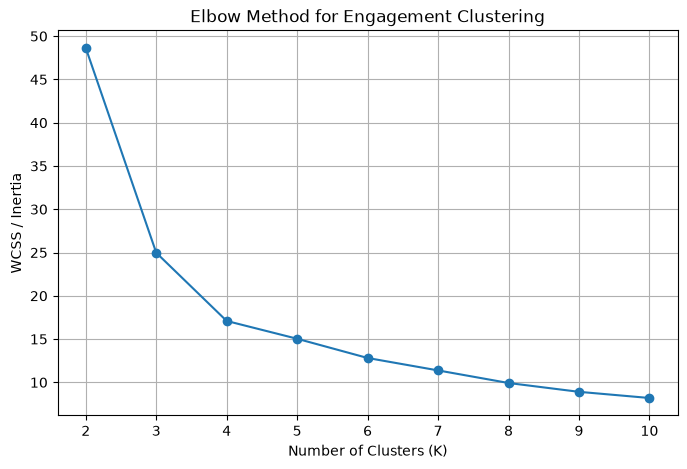

In [23]:
# ============================================================
# Objective 17: ELBOW METHOD FOR ENGAGEMENT CLUSTERING
# ============================================================

# ------------------------------------------------------------
# 1. Test different values of K
# ------------------------------------------------------------

wcss = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(engagement_scaled)

    wcss.append(kmeans.inertia_)


# ------------------------------------------------------------
# 2. Display WCSS values
# ------------------------------------------------------------

print("WCSS values:")

for k, value in zip(range(2, 11), wcss):
    print(f"K = {k} : WCSS = {value:.2f}")


# ------------------------------------------------------------
# 3. Plot Elbow Method
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    wcss,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.title("Elbow Method for Engagement Clustering")

plt.xticks(range(2, 11))
plt.grid(True)

plt.show()




Experience metrics created successfully!
Customer-level experience dataset created successfully!

Experience Dataset:


,MSISDN_Number,Avg_TCP_Retransmission,Avg_RTT,Handset_Type,Avg_Throughput
0,3.360171e+10,1.078479e+07,57.500000,Apple iPhone Se (A1723),35.000000
1,3.360171e+10,3.096170e+05,76.000000,Apple iPhone 6 (A1586),4896.000000
2,3.360171e+10,9.211635e+06,61.614647,Samsung Galaxy S8 Plus (Sm-G955F),3674.011482
3,3.360171e+10,1.078479e+07,17.000000,Apple iPhone 7 Plus (A1784),58.500000
4,3.360172e+10,1.078479e+07,63.729294,Samsung Galaxy S8 (Sm-G950F),38.000000



================ TCP RETRANSMISSION ANALYSIS ================

Top 10 TCP Retransmission Values:


0    2.584195e+07
1    2.531463e+07
2    2.530242e+07
3    2.523972e+07
4    2.519644e+07
5    2.517975e+07
6    2.517349e+07
7    2.515900e+07
8    2.512970e+07
9    2.511580e+07
Name: Avg_TCP_Retransmission, dtype: float64


Bottom 10 TCP Retransmission Values:


...

Avg_Throughput
7535.237287    7965
31.500000      3886
7.500000       3741
48.500000      1945
45.000000      1885
49.000000      1801
48.000000      1671
49.500000      1571
44.500000      1557
45.500000      1520
Name: count, dtype: int64


================ THROUGHPUT BY HANDSET TYPE ================
Top 10 Handset Types by Average Throughput:


,Handset_Type,Avg_Throughput
0,Xiaomi Communica. M1803E1A,25471.214323
1,Htc 2Q6E100,23746.500000
2,Huawei Y5 2017,22992.000000
3,Lephone U Pro,22834.500000
4,Huawei Vns-Dl00,22571.500000
5,Xiaomi Communica. B5,22183.000000
6,Samsung Galaxy On 7,21886.714323
7,Samsung Galaxy A6 Duos (Sm-A605G Ds),21476.000000
8,Shenzhen Chainwa. C70,21298.500000
9,Zyxel Communicat. Lte7460,20755.714323



================ TCP RETRANSMISSION BY HANDSET ================
Top 10 Handset Types by Average TCP Retransmission:


,Handset_Type,Avg_TCP_Retransmission
0,Samsung Galaxy Core 2 (Sm-G355X),2.327950e+07
1,A-Link Telecom I. Cubot Note S,2.070587e+07
2,Asustek Asus Zenfone Selfie Zd551Kl,1.920872e+07
3,Spa Condor Elect. Allure M1 Plus,1.588508e+07
4,Quartel Infotech. Maximus M84,1.564691e+07
5,Tcl Communicatio. Pixi 4 6 3G Android,1.543098e+07
6,Lg-M400Dy,1.420619e+07
7,Rim Blackberry Stl100-2 Z10 Rfh121Lw,1.412459e+07
8,Lg G6+,1.353974e+07
9,Samsung Galaxy J3 (Sm-J327),1.268490e+07


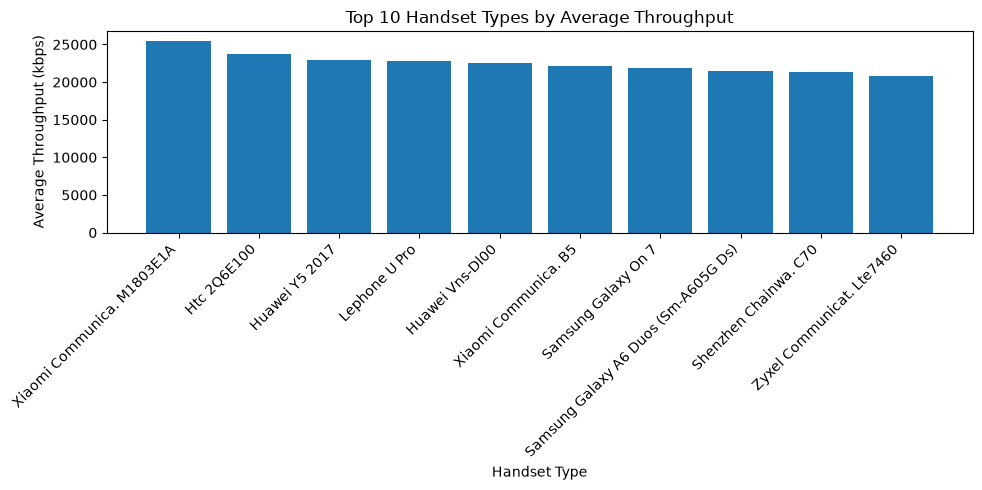

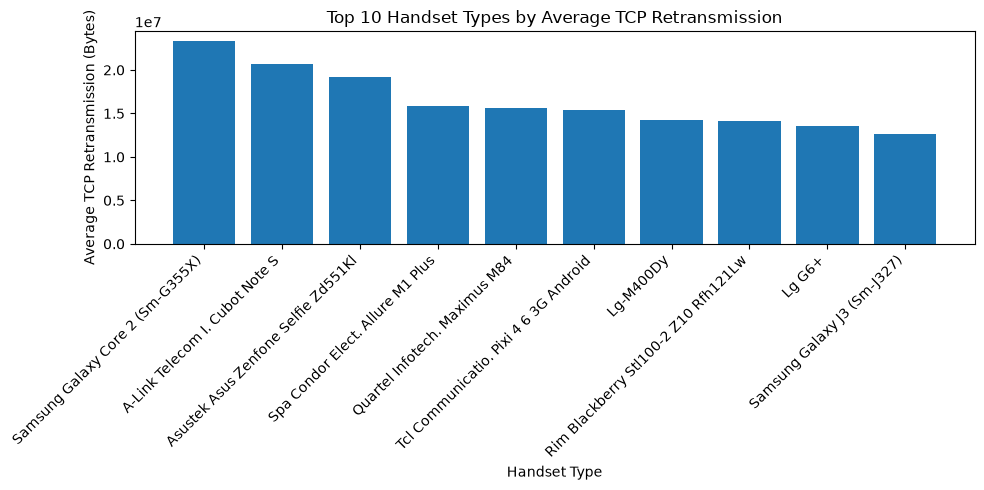

In [24]:
# ============================================================
# Objective 18: USER EXPERIENCE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Create row-level experience metrics
# ------------------------------------------------------------

# Average TCP retransmission from Download and Upload
df["Avg_TCP_Retransmission"] = df[
    ["TCP_DL_Retrans._Vol_Bytes", "TCP_UL_Retrans._Vol_Bytes"]
].mean(axis=1)

# Average RTT from Download and Upload
df["Avg_RTT"] = df[
    ["Avg_RTT_DL_ms", "Avg_RTT_UL_ms"]
].mean(axis=1)

# Average throughput from Download and Upload
df["Avg_Throughput"] = df[
    ["Avg_Bearer_TP_DL_kbps", "Avg_Bearer_TP_UL_kbps"]
].mean(axis=1)


print("Experience metrics created successfully!")


# ------------------------------------------------------------
# 2. Aggregate experience metrics per customer
# ------------------------------------------------------------

def get_mode(series):
    mode_values = series.dropna().mode()

    if len(mode_values) > 0:
        return mode_values.iloc[0]

    return np.nan


experience_df = (
    df.groupby("MSISDN_Number")
    .agg(
        Avg_TCP_Retransmission=("Avg_TCP_Retransmission", "mean"),
        Avg_RTT=("Avg_RTT", "mean"),
        Handset_Type=("Handset_Type", get_mode),
        Avg_Throughput=("Avg_Throughput", "mean")
    )
    .reset_index()
)


print("Customer-level experience dataset created successfully!")

print("\nExperience Dataset:")
display(experience_df.head())


# ------------------------------------------------------------
# 3. TCP retransmission analysis
# ------------------------------------------------------------

print("\n================ TCP RETRANSMISSION ANALYSIS ================")

top_10_tcp = (
    df["Avg_TCP_Retransmission"]
    .dropna()
    .nlargest(10)
    .reset_index(drop=True)
)

bottom_10_tcp = (
    df["Avg_TCP_Retransmission"]
    .dropna()
    .nsmallest(10)
    .reset_index(drop=True)
)

frequent_10_tcp = (
    df["Avg_TCP_Retransmission"]
    .dropna()
    .value_counts()
    .head(10)
)


print("\nTop 10 TCP Retransmission Values:")
display(top_10_tcp)

print("\nBottom 10 TCP Retransmission Values:")
display(bottom_10_tcp)

print("\n10 Most Frequent TCP Retransmission Values:")
display(frequent_10_tcp)


# ------------------------------------------------------------
# 4. RTT analysis
# ------------------------------------------------------------

print("\n================ RTT ANALYSIS ================")

top_10_rtt = (
    df["Avg_RTT"]
    .dropna()
    .nlargest(10)
    .reset_index(drop=True)
)

bottom_10_rtt = (
    df["Avg_RTT"]
    .dropna()
    .nsmallest(10)
    .reset_index(drop=True)
)

frequent_10_rtt = (
    df["Avg_RTT"]
    .dropna()
    .value_counts()
    .head(10)
)


print("\nTop 10 RTT Values:")
display(top_10_rtt)

print("\nBottom 10 RTT Values:")
display(bottom_10_rtt)

print("\n10 Most Frequent RTT Values:")
display(frequent_10_rtt)


# ------------------------------------------------------------
# 5. Throughput analysis
# ------------------------------------------------------------

print("\n================ THROUGHPUT ANALYSIS ================")

top_10_throughput = (
    df["Avg_Throughput"]
    .dropna()
    .nlargest(10)
    .reset_index(drop=True)
)

bottom_10_throughput = (
    df["Avg_Throughput"]
    .dropna()
    .nsmallest(10)
    .reset_index(drop=True)
)

frequent_10_throughput = (
    df["Avg_Throughput"]
    .dropna()
    .value_counts()
    .head(10)
)


print("\nTop 10 Throughput Values:")
display(top_10_throughput)

print("\nBottom 10 Throughput Values:")
display(bottom_10_throughput)

print("\n10 Most Frequent Throughput Values:")
display(frequent_10_throughput)


# ------------------------------------------------------------
# 6. Average throughput by handset type
# ------------------------------------------------------------

throughput_by_handset = (
    experience_df
    .groupby("Handset_Type")["Avg_Throughput"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("\n================ THROUGHPUT BY HANDSET TYPE ================")

print("Top 10 Handset Types by Average Throughput:")
display(throughput_by_handset.head(10))


# ------------------------------------------------------------
# 7. Average TCP retransmission by handset type
# ------------------------------------------------------------

tcp_by_handset = (
    experience_df
    .groupby("Handset_Type")["Avg_TCP_Retransmission"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

print("\n================ TCP RETRANSMISSION BY HANDSET ================")

print("Top 10 Handset Types by Average TCP Retransmission:")
display(tcp_by_handset.head(10))


# ------------------------------------------------------------
# 8. Plot average throughput by top 10 handset types
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    throughput_by_handset.head(10)["Handset_Type"].astype(str),
    throughput_by_handset.head(10)["Avg_Throughput"]
)

plt.xlabel("Handset Type")
plt.ylabel("Average Throughput (kbps)")
plt.title("Top 10 Handset Types by Average Throughput")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 9. Plot average TCP retransmission by top 10 handset types
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.bar(
    tcp_by_handset.head(10)["Handset_Type"].astype(str),
    tcp_by_handset.head(10)["Avg_TCP_Retransmission"]
)

plt.xlabel("Handset Type")
plt.ylabel("Average TCP Retransmission (Bytes)")
plt.title("Top 10 Handset Types by Average TCP Retransmission")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()




In [25]:
# ============================================================
# Objective 19: EXPERIENCE K-MEANS CLUSTERING
# ============================================================

# ------------------------------------------------------------
# 1. Select numerical experience features
# ------------------------------------------------------------

experience_features = [
    "Avg_TCP_Retransmission",
    "Avg_RTT",
    "Avg_Throughput"
]

print("Experience features selected successfully!")


# ------------------------------------------------------------
# 2. Prepare experience clustering data
# ------------------------------------------------------------

experience_clustering = experience_df[
    ["MSISDN_Number"] + experience_features
].copy()

print("Experience clustering dataset created successfully!")

print("\nExperience clustering data:")
display(experience_clustering.head())


# ------------------------------------------------------------
# 3. Check missing values
# ------------------------------------------------------------

print("\nMissing values:")
display(
    experience_clustering[experience_features].isnull().sum()
)


# ------------------------------------------------------------
# 4. Standardize experience features
# ------------------------------------------------------------

scaler_experience = StandardScaler()

experience_scaled = scaler_experience.fit_transform(
    experience_clustering[experience_features]
)

print("\nExperience features standardized successfully!")


# ------------------------------------------------------------
# 5. Apply K-Means with K = 3
# ------------------------------------------------------------

experience_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

experience_clustering["Experience_Cluster"] = (
    experience_kmeans.fit_predict(experience_scaled)
)

print("Experience K-Means clustering completed successfully!")


# ------------------------------------------------------------
# 6. Display cluster distribution
# ------------------------------------------------------------

print("\nCluster Distribution:")

display(
    experience_clustering["Experience_Cluster"]
    .value_counts()
    .sort_index()
)


# ------------------------------------------------------------
# 7. Calculate cluster averages
# ------------------------------------------------------------

print("\nExperience Cluster Summary:")

experience_cluster_summary = (
    experience_clustering
    .groupby("Experience_Cluster")[experience_features]
    .mean()
)

display(experience_cluster_summary)


# ------------------------------------------------------------
# 8. Add cluster number to experience_df
# ------------------------------------------------------------

experience_df["Experience_Cluster"] = (
    experience_clustering["Experience_Cluster"].values
)


# ------------------------------------------------------------
# 9. Display final experience data
# ------------------------------------------------------------

print("\nExperience data with cluster:")
display(experience_df.head())




Experience features selected successfully!
Experience clustering dataset created successfully!

Experience clustering data:


,MSISDN_Number,Avg_TCP_Retransmission,Avg_RTT,Avg_Throughput
0,3.360171e+10,1.078479e+07,57.500000,35.000000
1,3.360171e+10,3.096170e+05,76.000000,4896.000000
2,3.360171e+10,9.211635e+06,61.614647,3674.011482
3,3.360171e+10,1.078479e+07,17.000000,58.500000
4,3.360172e+10,1.078479e+07,63.729294,38.000000



Missing values:


Avg_TCP_Retransmission    0
Avg_RTT                   0
Avg_Throughput            0
dtype: int64


Experience features standardized successfully!
Experience K-Means clustering completed successfully!

Cluster Distribution:


Experience_Cluster
0    37186
1    22555
2    30296
Name: count, dtype: int64


Experience Cluster Summary:


,Avg_TCP_Retransmission,Avg_RTT,Avg_Throughput
Experience_Cluster,,,
0,1.018290e+07,21.596433,779.941234
1,1.008284e+07,64.152106,1242.279036
2,1.912161e+06,41.030080,9287.063081



Experience data with cluster:


,MSISDN_Number,Avg_TCP_Retransmission,Avg_RTT,Handset_Type,Avg_Throughput,Experience_Cluster
0,3.360171e+10,1.078479e+07,57.500000,Apple iPhone Se (A1723),35.000000,1
1,3.360171e+10,3.096170e+05,76.000000,Apple iPhone 6 (A1586),4896.000000,2
2,3.360171e+10,9.211635e+06,61.614647,Samsung Galaxy S8 Plus (Sm-G955F),3674.011482,1
3,3.360171e+10,1.078479e+07,17.000000,Apple iPhone 7 Plus (A1784),58.500000,0
4,3.360172e+10,1.078479e+07,63.729294,Samsung Galaxy S8 (Sm-G950F),38.000000,1


In [26]:
# ============================================================
# Objective 20: USER SATISFACTION SCORE
# ============================================================

print("Starting Phase 20 - Satisfaction Score...")
print()


# ============================================================
# 1. PREPARE ENGAGEMENT DATA
# ============================================================

engagement_features = [
    "Total_Sessions",
    "Total_Duration_ms",
    "Total_DL_Bytes",
    "Total_UL_Bytes"
]

engagement_data = customer_df[
    ["MSISDN_Number"] + engagement_features + ["Engagement_Cluster"]
].copy()

print("Engagement data prepared successfully!")


# ============================================================
# 2. STANDARDIZE ENGAGEMENT FEATURES
# ============================================================

engagement_scaler = StandardScaler()

engagement_scaled = engagement_scaler.fit_transform(
    engagement_data[engagement_features]
)

print("Engagement features standardized successfully!")


# ============================================================
# 3. IDENTIFY LESS-ENGAGED CLUSTER
# ============================================================

engagement_data["_Engagement_Mean"] = (
    engagement_scaled.mean(axis=1)
)

cluster_engagement_level = (
    engagement_data
    .groupby("Engagement_Cluster")["_Engagement_Mean"]
    .mean()
)

less_engaged_cluster = cluster_engagement_level.idxmin()

print("\nLess-engaged cluster:")
print(less_engaged_cluster)


# ============================================================
# 4. CALCULATE ENGAGEMENT SCORE
# ============================================================

less_engaged_center = (
    engagement_data[
        engagement_data["Engagement_Cluster"] == less_engaged_cluster
    ][engagement_features]
)

less_engaged_center = engagement_scaler.transform(
    less_engaged_center
).mean(axis=0)

engagement_data["Engagement_Score"] = np.linalg.norm(
    engagement_scaled - less_engaged_center,
    axis=1
)

print("\nEngagement scores calculated successfully!")


# ============================================================
# 5. PREPARE EXPERIENCE DATA
# ============================================================

experience_features = [
    "Avg_TCP_Retransmission",
    "Avg_RTT",
    "Avg_Throughput"
]

experience_data = experience_df[
    ["MSISDN_Number"] + experience_features + ["Experience_Cluster"]
].copy()

print("Experience data prepared successfully!")


# ============================================================
# 6. STANDARDIZE EXPERIENCE FEATURES
# ============================================================

experience_scaler = StandardScaler()

experience_scaled = experience_scaler.fit_transform(
    experience_data[experience_features]
)

print("Experience features standardized successfully!")


# ============================================================
# 7. IDENTIFY WORST EXPERIENCE CLUSTER
# ============================================================

# Higher TCP retransmission = worse
# Higher RTT = worse
# Higher throughput = better

experience_data["_Experience_Quality"] = (
    experience_scaled[:, 0]
    + experience_scaled[:, 1]
    - experience_scaled[:, 2]
)

cluster_experience_quality = (
    experience_data
    .groupby("Experience_Cluster")["_Experience_Quality"]
    .mean()
)

worst_experience_cluster = (
    cluster_experience_quality.idxmax()
)

print("\nWorst experience cluster:")
print(worst_experience_cluster)


# ============================================================
# 8. CALCULATE EXPERIENCE SCORE
# ============================================================

worst_experience_center = (
    experience_data[
        experience_data["Experience_Cluster"]
        == worst_experience_cluster
    ][experience_features]
)

worst_experience_center = experience_scaler.transform(
    worst_experience_center
).mean(axis=0)

experience_data["Experience_Score"] = np.linalg.norm(
    experience_scaled - worst_experience_center,
    axis=1
)

print("Experience scores calculated successfully!")


# ============================================================
# 9. COMBINE ENGAGEMENT + EXPERIENCE
# ============================================================

satisfaction_df = engagement_data[
    ["MSISDN_Number", "Engagement_Score"]
].merge(
    experience_data[
        ["MSISDN_Number", "Experience_Score"]
    ],
    on="MSISDN_Number",
    how="inner"
)

print("\nEngagement and experience data combined successfully!")


# ============================================================
# 10. CALCULATE SATISFACTION SCORE
# ============================================================

satisfaction_df["Satisfaction_Score"] = (
    satisfaction_df["Engagement_Score"]
    + satisfaction_df["Experience_Score"]
) / 2

print("Satisfaction scores calculated successfully!")


# ============================================================
# 11. DISPLAY SATISFACTION RESULTS
# ============================================================

print("\n============================================================")
print("SATISFACTION SCORE RESULTS")
print("============================================================")

display(
    satisfaction_df[
        [
            "MSISDN_Number",
            "Engagement_Score",
            "Experience_Score",
            "Satisfaction_Score"
        ]
    ].head(10)
)


# ============================================================
# 12. DISPLAY SUMMARY STATISTICS
# ============================================================

print("\nSatisfaction Score Summary:")

display(
    satisfaction_df[
        [
            "Engagement_Score",
            "Experience_Score",
            "Satisfaction_Score"
        ]
    ].describe()
)


# ============================================================
# 13. CHECK DATASET
# ============================================================

print("\nSatisfaction Dataset Shape:")
print(satisfaction_df.shape)

print("\nMissing Values:")

display(
    satisfaction_df.isnull().sum()
)



Starting Phase 20 - Satisfaction Score...

Engagement data prepared successfully!
Engagement features standardized successfully!

Less-engaged cluster:
0

Engagement scores calculated successfully!
Experience data prepared successfully!
Experience features standardized successfully!

Worst experience cluster:
1
Experience scores calculated successfully!

Engagement and experience data combined successfully!
Satisfaction scores calculated successfully!

SATISFACTION SCORE RESULTS


,MSISDN_Number,Engagement_Score,Experience_Score,Satisfaction_Score
0,3.360171e+10,0.010012,0.406740,0.208376
1,3.360171e+10,0.011765,2.325913,1.168839
2,3.360171e+10,0.031223,0.479225,0.255224
3,3.360171e+10,0.014260,2.225845,1.120052
4,3.360172e+10,0.008682,0.261398,0.135040
5,3.360172e+10,0.023814,1.749727,0.886770
6,3.360172e+10,0.026726,2.263971,1.145349
7,3.360172e+10,0.007010,2.086346,1.046678
8,3.360172e+10,0.031875,1.645540,0.838707
9,3.360172e+10,0.010798,0.979978,0.495388



Satisfaction Score Summary:


,Engagement_Score,Experience_Score,Satisfaction_Score
count,90037.000000,90037.000000,90037.000000
mean,0.023408,1.967539,0.995473
std,1.999918,1.045827,1.127646
min,0.001843,0.076936,0.042994
25%,0.008306,1.387444,0.701689
50%,0.011587,2.134634,1.079712
75%,0.017684,2.549036,1.281465
max,600.092706,5.360120,300.760298



Satisfaction Dataset Shape:
(90037, 4)

Missing Values:


MSISDN_Number         0
Engagement_Score      0
Experience_Score      0
Satisfaction_Score    0
dtype: int64

In [27]:
# ============================================================
# Objective 21: - REGRESSION MODEL FOR SATISFACTION
# ============================================================


print("Starting Satisfaction Regression Model...")
print()


# ============================================================
# 1. SELECT INPUT AND TARGET VARIABLES
# ============================================================

X = satisfaction_df[
    ["Engagement_Score", "Experience_Score"]
]

y = satisfaction_df[
    "Satisfaction_Score"
]

print("Regression features selected successfully!")

print("\nInput features:")
print(X.columns.tolist())

print("\nTarget variable:")
print("Satisfaction_Score")


# ============================================================
# 2. SPLIT DATA INTO TRAINING AND TESTING DATA
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nData split completed successfully!")

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# 3. CREATE LINEAR REGRESSION MODEL
# ============================================================

regression_model = LinearRegression()

regression_model.fit(
    X_train,
    y_train
)

print("\nLinear Regression model trained successfully!")


# ============================================================
# 4. MAKE PREDICTIONS
# ============================================================

y_pred = regression_model.predict(X_test)

print("Satisfaction predictions generated successfully!")


# ============================================================
# 5. CALCULATE MODEL METRICS
# ============================================================

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)


# ============================================================
# 6. DISPLAY MODEL PERFORMANCE
# ============================================================

print("\n============================================================")
print("REGRESSION MODEL PERFORMANCE")
print("============================================================")

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")


# ============================================================
# 7. DISPLAY MODEL COEFFICIENTS
# ============================================================

print("\n============================================================")
print("REGRESSION COEFFICIENTS")
print("============================================================")

coefficient_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": regression_model.coef_
})

display(coefficient_df)


# ============================================================
# 8. DISPLAY INTERCEPT
# ============================================================

print("Intercept:", regression_model.intercept_)


# ============================================================
# 9. DISPLAY ACTUAL VS PREDICTED VALUES
# ============================================================

prediction_df = pd.DataFrame({
    "Actual_Satisfaction": y_test.values,
    "Predicted_Satisfaction": y_pred
})

print("\n============================================================")
print("ACTUAL VS PREDICTED SATISFACTION")
print("============================================================")

display(
    prediction_df.head(10)
)




Starting Satisfaction Regression Model...

Regression features selected successfully!

Input features:
['Engagement_Score', 'Experience_Score']

Target variable:
Satisfaction_Score

Data split completed successfully!
Training samples: 72029
Testing samples: 18008

Linear Regression model trained successfully!
Satisfaction predictions generated successfully!

REGRESSION MODEL PERFORMANCE
Mean Absolute Error (MAE): 0.0000
Root Mean Squared Error (RMSE): 0.0000
R² Score: 1.0000

REGRESSION COEFFICIENTS


,Feature,Coefficient
0,Engagement_Score,0.5
1,Experience_Score,0.5


Intercept: 3.3306690738754696e-16

ACTUAL VS PREDICTED SATISFACTION


,Actual_Satisfaction,Predicted_Satisfaction
0,0.151605,0.151605
1,1.163738,1.163738
2,0.885977,0.885977
3,2.127097,2.127097
4,1.010000,1.010000
5,2.256638,2.256638
6,1.151903,1.151903
7,1.285872,1.285872
8,1.801620,1.801620
9,1.348308,1.348308


For SQL checking the customer shape

In [28]:
print("customer_df shape:", customer_df.shape)
print("\ncustomer_df columns:")
print(customer_df.columns.tolist())

customer_df shape: (90037, 9)

customer_df columns:
['MSISDN_Number', 'Total_Sessions', 'Total_Duration_ms', 'Total_DL_Bytes', 'Total_UL_Bytes', 'Avg_RTT_DL_ms', 'Avg_RTT_UL_ms', 'Total_Traffic_Bytes', 'Engagement_Cluster']


In [29]:
# Prepare final scores from satisfaction_df

final_scores = satisfaction_df[
    [
        "MSISDN_Number",
        "Engagement_Score",
        "Experience_Score",
        "Satisfaction_Score"
    ]
]

print("Final scores prepared successfully!")
print("Shape:", final_scores.shape)
print("\nColumns:")
print(final_scores.columns.tolist())

print("\nFirst 5 rows:")
print(final_scores.head())

Final scores prepared successfully!
Shape: (90037, 4)

Columns:
['MSISDN_Number', 'Engagement_Score', 'Experience_Score', 'Satisfaction_Score']

First 5 rows:
   MSISDN_Number  Engagement_Score  Experience_Score  Satisfaction_Score
0   3.360171e+10          0.010012          0.406740            0.208376
1   3.360171e+10          0.011765          2.325913            1.168839
2   3.360171e+10          0.031223          0.479225            0.255224
3   3.360171e+10          0.014260          2.225845            1.120052
4   3.360172e+10          0.008682          0.261398            0.135040


1.Creates df_1000_sql, which is used by your SQL Server upload cell.
2.converts the large ID columns to text so SQL Server can store them safely.
3.Does not duplicate another unnecessary SQL connection.
4.Prepares the data for TelecomData.

In [30]:
# Create a separate copy for SQL upload
df_1000_sql = df.head(1000).copy()

# Convert very large ID columns to text
id_columns = [
    "Bearer_Id",
    "IMSI",
    "MSISDN_Number",
    "IMEI"
]

for col in id_columns:
    if col in df_1000_sql.columns:
        df_1000_sql[col] = df_1000_sql[col].astype(str)

print("SQL upload dataframe ready")
print("Rows:", len(df_1000_sql))
print("Columns:", len(df_1000_sql.columns))

SQL upload dataframe ready
Rows: 1000
Columns: 66


1. SQL Server engine

In [31]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

connection_string = quote_plus(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=.\\SQLEXPRESS;"
    "DATABASE=TelecomDB;"
    "Trusted_Connection=yes;"
)

engine = create_engine(
    f"mssql+pyodbc:///?odbc_connect={connection_string}"
)

print("SQL Server engine created successfully!")

SQL Server engine created successfully!


2. Upload TelecomData
Jupyter → SQL Server upload.

In [32]:
df_1000_sql.to_sql(
    "TelecomData",
    con=engine,
    schema="dbo",
    if_exists="replace",
    index=False,
    chunksize=100
)

print("Successfully uploaded 1000 rows to SQL Server!")

Successfully uploaded 1000 rows to SQL Server!


3. Prepare CustomerScores

In [33]:
scores_sql = final_scores.copy()

scores_sql["MSISDN_Number"] = scores_sql["MSISDN_Number"].astype(str)

print("Score data ready for SQL Server")
print("Rows:", len(scores_sql))
print("Columns:", len(scores_sql.columns))

display(scores_sql.head())

Score data ready for SQL Server
Rows: 90037
Columns: 4


,MSISDN_Number,Engagement_Score,Experience_Score,Satisfaction_Score
0,33601712373.0,0.010012,0.406740,0.208376
1,33601712551.0,0.011765,2.325913,1.168839
2,33601713789.0,0.031223,0.479225,0.255224
3,33601714799.0,0.014260,2.225845,1.120052
4,33601717042.0,0.008682,0.261398,0.135040


4. Upload CustomerScores

In [34]:
scores_sql.to_sql(
    "CustomerScores",
    con=engine,
    schema="dbo",
    if_exists="replace",
    index=False,
    chunksize=1000
)

print("Customer scores uploaded successfully!")

Customer scores uploaded successfully!
